# Projeto Final IAP — Parte 2: Classificação Probabilística e Quantificação de Incerteza

**Objectivo:** Treinar e avaliar classificadores probabilísticos para prever o resultado dos jogos (H/D/A), com foco em:
1. Naive Bayes (Gaussiano e Categórico)
2. Conformal Prediction
3. Calibração dos modelos
4. Optimização Bayesiana de hiperparâmetros

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    brier_score_loss, log_loss
)
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from skopt import BayesSearchCV
from mapie.classification import SplitConformalClassifier
from skopt.space import Real, Categorical

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid', palette='muted')
os.makedirs('plots', exist_ok=True)
print('Packages loaded.')


Packages loaded.


## 1. Preparação dos Dados e Split Temporal

In [2]:
df = pd.read_csv('dataset.csv', parse_dates=['date'])

# Features numéricas para GaussianNB
NUM_FEATURES = [
    'ht_form_points', 'ht_form_goals_scored', 'ht_form_goals_conceded', 'ht_form_wins',
    'at_form_points', 'at_form_goals_scored', 'at_form_goals_conceded', 'at_form_wins',
    'ht_home_form_points', 'ht_home_form_goals_scored',
    'at_away_form_points', 'at_away_form_goals_scored',
    'h2h_home_wins', 'h2h_draws', 'h2h_away_wins',
]

# Features categóricas para CategoricalNB
CAT_FEATURES = ['ht_form', 'at_form', 'ht_attack', 'at_attack', 'h2h_dominance', 'odds_favorite']

TARGET = 'result'

# Split temporal: treino 2006–2021, teste 2022–2026
train_df = df[df['date'] < '2022-01-01'].dropna(subset=NUM_FEATURES + CAT_FEATURES + [TARGET])
test_df  = df[df['date'] >= '2022-01-01'].dropna(subset=NUM_FEATURES + CAT_FEATURES + [TARGET])

print(f'Treino: {len(train_df)} jogos ({train_df["date"].min().date()} → {train_df["date"].max().date()})')
print(f'Teste:  {len(test_df)}  jogos ({test_df["date"].min().date()} → {test_df["date"].max().date()})')
print(f'Distribuição treino:\n{train_df[TARGET].value_counts()}')

Treino: 4331 jogos (2006-01-06 → 2021-12-30)
Teste:  1252  jogos (2022-01-02 → 2026-01-26)
Distribuição treino:
result
H    1919
A    1306
D    1106
Name: count, dtype: int64


In [3]:
# Preparar arrays para modelos numéricos
X_train_num = train_df[NUM_FEATURES].values
X_test_num  = test_df[NUM_FEATURES].values
y_train = train_df[TARGET].values
y_test  = test_df[TARGET].values

# Preparar arrays para modelos categóricos (ordinal encoding)
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_cat = oe.fit_transform(train_df[CAT_FEATURES].astype(str))
X_test_cat  = oe.transform(test_df[CAT_FEATURES].astype(str))

# Combinar features (numérico + categórico codificado)
X_train_all = np.hstack([X_train_num, X_train_cat])
X_test_all  = np.hstack([X_test_num, X_test_cat])

classes = np.unique(y_train)
print(f'Classes: {classes}')
print(f'Feature shape (treino): {X_train_all.shape}')

Classes: ['A' 'D' 'H']
Feature shape (treino): (4331, 21)


## 2. Treino e Avaliação do Naive Bayes

In [4]:
# Gaussian Naive Bayes (features numéricas)
gnb = GaussianNB()
gnb.fit(X_train_num, y_train)
y_pred_gnb = gnb.predict(X_test_num)
y_proba_gnb = gnb.predict_proba(X_test_num)

acc_gnb = accuracy_score(y_test, y_pred_gnb)
print(f'=== Gaussian Naive Bayes (features numéricas) ===')
print(f'Accuracy: {acc_gnb:.3f}')
print(classification_report(y_test, y_pred_gnb, target_names=gnb.classes_))

=== Gaussian Naive Bayes (features numéricas) ===
Accuracy: 0.532
              precision    recall  f1-score   support

           A       0.58      0.56      0.57       406
           D       0.32      0.38      0.35       299
           H       0.64      0.59      0.62       547

    accuracy                           0.53      1252
   macro avg       0.51      0.51      0.51      1252
weighted avg       0.55      0.53      0.54      1252



In [5]:
# Categorical Naive Bayes (features discretizadas)
# CategoricalNB requer valores inteiros >= 0
X_train_cat_adj = np.maximum(X_train_cat, 0).astype(int)
X_test_cat_adj  = np.maximum(X_test_cat, 0).astype(int)

cnb = CategoricalNB(alpha=1.0)  # Laplace smoothing
cnb.fit(X_train_cat_adj, y_train)
y_pred_cnb = cnb.predict(X_test_cat_adj)
y_proba_cnb = cnb.predict_proba(X_test_cat_adj)

acc_cnb = accuracy_score(y_test, y_pred_cnb)
print(f'=== Categorical Naive Bayes (features discretizadas) ===')
print(f'Accuracy: {acc_cnb:.3f}')
print(classification_report(y_test, y_pred_cnb, target_names=cnb.classes_))

=== Categorical Naive Bayes (features discretizadas) ===
Accuracy: 0.568
              precision    recall  f1-score   support

           A       0.60      0.60      0.60       406
           D       0.34      0.12      0.18       299
           H       0.58      0.79      0.67       547

    accuracy                           0.57      1252
   macro avg       0.51      0.50      0.48      1252
weighted avg       0.53      0.57      0.53      1252



In [6]:
# Gaussian NB com todas as features
gnb_all = GaussianNB()
gnb_all.fit(X_train_all, y_train)
y_pred_gnb_all = gnb_all.predict(X_test_all)
y_proba_gnb_all = gnb_all.predict_proba(X_test_all)

acc_gnb_all = accuracy_score(y_test, y_pred_gnb_all)
print(f'=== Gaussian Naive Bayes (todas as features) ===')
print(f'Accuracy: {acc_gnb_all:.3f}')
print(classification_report(y_test, y_pred_gnb_all, target_names=gnb_all.classes_))

=== Gaussian Naive Bayes (todas as features) ===
Accuracy: 0.546
              precision    recall  f1-score   support

           A       0.60      0.56      0.58       406
           D       0.33      0.34      0.34       299
           H       0.63      0.65      0.64       547

    accuracy                           0.55      1252
   macro avg       0.52      0.52      0.52      1252
weighted avg       0.55      0.55      0.55      1252



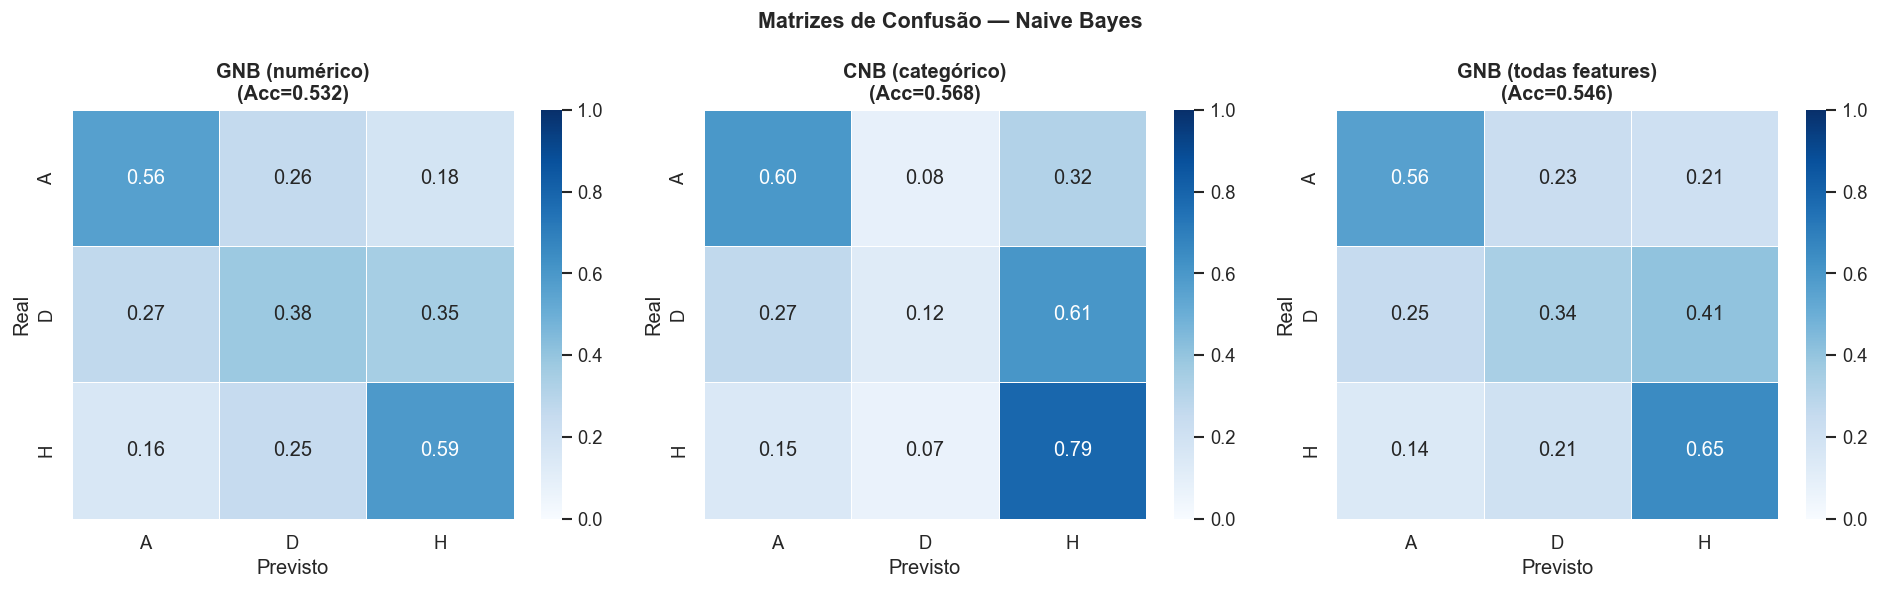

In [7]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

model_results = [
    ('GNB (numérico)', gnb.classes_, y_pred_gnb),
    ('CNB (categórico)', cnb.classes_, y_pred_cnb),
    ('GNB (todas features)', gnb_all.classes_, y_pred_gnb_all),
]

for ax, (title, cls, preds) in zip(axes, model_results):
    cm = confusion_matrix(y_test, preds, labels=cls)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_pct, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=cls, yticklabels=cls, ax=ax,
                linewidths=0.5, vmin=0, vmax=1)
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')
    ax.set_title(f'{title}\n(Acc={accuracy_score(y_test, preds):.3f})', fontweight='bold')

plt.suptitle('Matrizes de Confusão — Naive Bayes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p2_confusion_matrices.png', bbox_inches='tight')
plt.show()

## 3. Conformal Prediction

A Conformal Prediction produz **conjuntos de previsão** (*prediction sets*) com garantia de cobertura.
Para nível de confiança `1 - α`, garante-se empiricamente que o conjunto contém o resultado real em pelo menos `1 - α` das vezes.

In [8]:
# Usar GaussianNB com todas as features como base
# Dividir treino: 80% treino base, 20% calibração
split_idx = int(len(X_train_all) * 0.8)
X_calib = X_train_all[split_idx:]
y_calib = y_train[split_idx:]
X_train_cp = X_train_all[:split_idx]
y_train_cp = y_train[:split_idx]

# Treinar modelo base no subset de treino
gnb_cp = GaussianNB()
gnb_cp.fit(X_train_cp, y_train_cp)

# Predições para diferentes níveis de confiança
# MAPIE 1.3.0: mudar confidence_level e reconformalize

alphas_targets = [0.95, 0.90, 0.80]  # 95%, 90%, 80% confiança
results_cp = []

for conf_level in alphas_targets:
    # Criar novo SplitConformalClassifier com este nível de confiança
    clf_cp = SplitConformalClassifier(
        estimator=gnb_cp, confidence_level=conf_level,
        conformity_score='lac', prefit=True, random_state=42
    )
    clf_cp.conformalize(X_calib, y_calib)
    
    # predict_set retorna (point_preds, prediction_sets)
    # prediction_sets shape: (n_samples, n_classes, 1)
    _, ps_result = clf_cp.predict_set(X_test_all)
    ps = ps_result[:, :, 0]  # shape (n_samples, n_classes)
    
    # Cobertura: label real está no prediction set?
    classes_list = list(gnb_cp.classes_)
    coverage = np.mean([
        ps[i, classes_list.index(y_test[i])]
        for i in range(len(y_test))
    ])
    avg_set_size = ps.sum(axis=1).mean()
    alpha = 1 - conf_level
    
    results_cp.append({
        'alpha': alpha,
        'target_coverage': conf_level,
        'empirical_coverage': float(coverage),
        'avg_set_size': float(avg_set_size),
        'ps': ps
    })
    print(f'confidence={conf_level:.2f} (α={alpha:.2f}) | '
          f'Cobertura empírica: {coverage:.3f} | '
          f'Tamanho médio do conjunto: {avg_set_size:.2f}')

cp_results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'ps'} for r in results_cp])
print(cp_results_df.to_string(index=False))

# prediction sets for 90% confidence level (for visualisation)
ps_90 = results_cp[1]['ps']  # 90% confidence


confidence=0.95 (α=0.05) | Cobertura empírica: 0.953 | Tamanho médio do conjunto: 2.55
confidence=0.90 (α=0.10) | Cobertura empírica: 0.894 | Tamanho médio do conjunto: 2.18
confidence=0.80 (α=0.20) | Cobertura empírica: 0.808 | Tamanho médio do conjunto: 1.83
 alpha  target_coverage  empirical_coverage  avg_set_size
  0.05             0.95            0.952875      2.550319
  0.10             0.90            0.893770      2.183706
  0.20             0.80            0.807508      1.834665


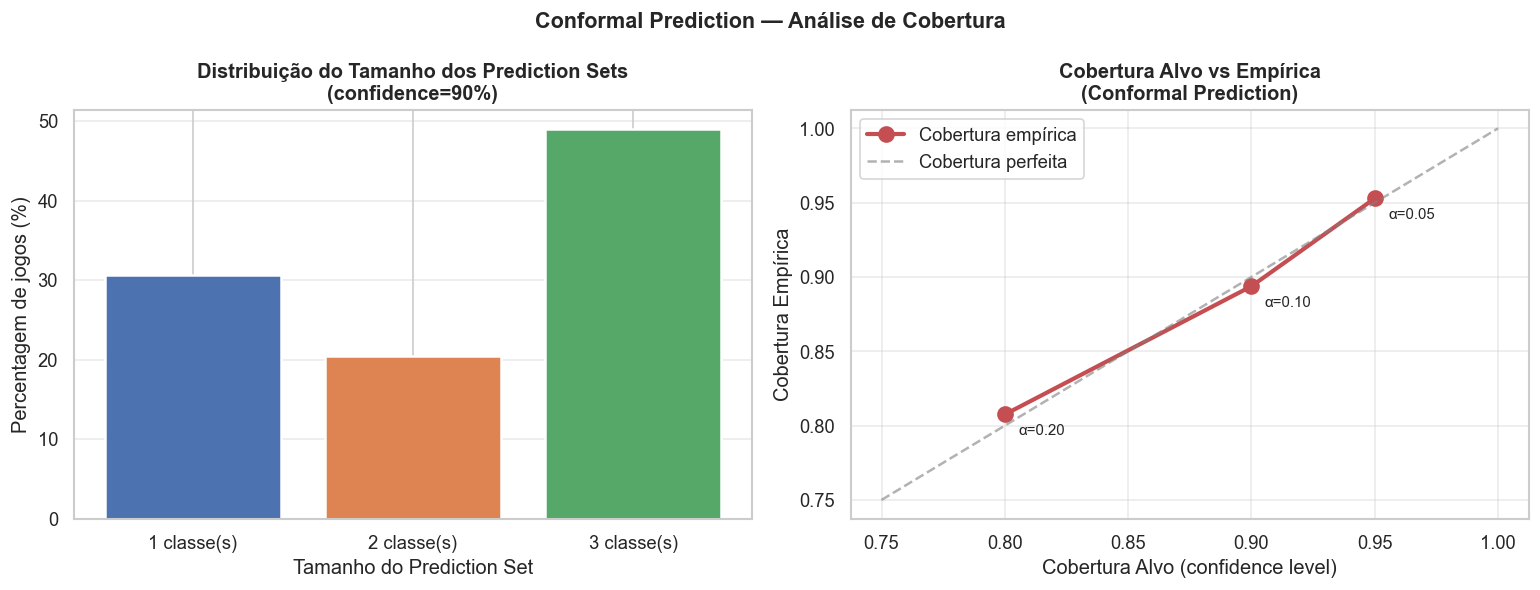

In [9]:
# Visualização dos prediction sets para confidence=0.90
set_sizes = ps_90.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribuição do tamanho dos conjuntos
unique_sizes, counts = np.unique(set_sizes, return_counts=True)
colors_pie = ['#4C72B0', '#DD8452', '#55A868']
axes[0].bar(unique_sizes.astype(int), counts / len(set_sizes) * 100,
            color=colors_pie[:len(unique_sizes)], edgecolor='white', linewidth=1.5)
axes[0].set_xlabel('Tamanho do Prediction Set')
axes[0].set_ylabel('Percentagem de jogos (%)')
axes[0].set_xticks(unique_sizes.astype(int))
axes[0].set_xticklabels([f'{int(s)} classe(s)' for s in unique_sizes])
axes[0].set_title('Distribuição do Tamanho dos Prediction Sets\n(confidence=90%)', fontweight='bold')
axes[0].grid(axis='y', alpha=0.4)

# Cobertura vs alpha
axes[1].plot([r['target_coverage'] for r in results_cp],
             [r['empirical_coverage'] for r in results_cp],
             'o-', color='#C44E52', linewidth=2.5, markersize=9, label='Cobertura empírica')
axes[1].plot([0.75, 1.0], [0.75, 1.0], '--', color='gray', alpha=0.6, label='Cobertura perfeita')
for r in results_cp:
    axes[1].annotate(f'α={r["alpha"]:.2f}',
                     (r['target_coverage'], r['empirical_coverage']),
                     textcoords='offset points', xytext=(8, -12), fontsize=9)
axes[1].set_xlabel('Cobertura Alvo (confidence level)')
axes[1].set_ylabel('Cobertura Empírica')
axes[1].set_title('Cobertura Alvo vs Empírica\n(Conformal Prediction)', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.4)

plt.suptitle('Conformal Prediction — Análise de Cobertura', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p2_conformal_prediction.png', bbox_inches='tight')
plt.show()


## 4. Calibração dos Modelos

A calibração avalia se as probabilidades previstas correspondem às frequências reais.
Um modelo bem calibrado que prevê P=0.7 deve estar correcto em 70% dos casos.

In [10]:
# Calibração: GaussianNB puro vs Platt Scaling vs Isotonic Regression
gnb_platt = CalibratedClassifierCV(GaussianNB(), method='sigmoid', cv=5)
gnb_iso   = CalibratedClassifierCV(GaussianNB(), method='isotonic', cv=5)

gnb_platt.fit(X_train_all, y_train)
gnb_iso.fit(X_train_all, y_train)

y_proba_platt = gnb_platt.predict_proba(X_test_all)
y_proba_iso   = gnb_iso.predict_proba(X_test_all)

print('Modelos calibrados.')
print(f'Classes: {gnb_all.classes_}')

Modelos calibrados.
Classes: ['A' 'D' 'H']


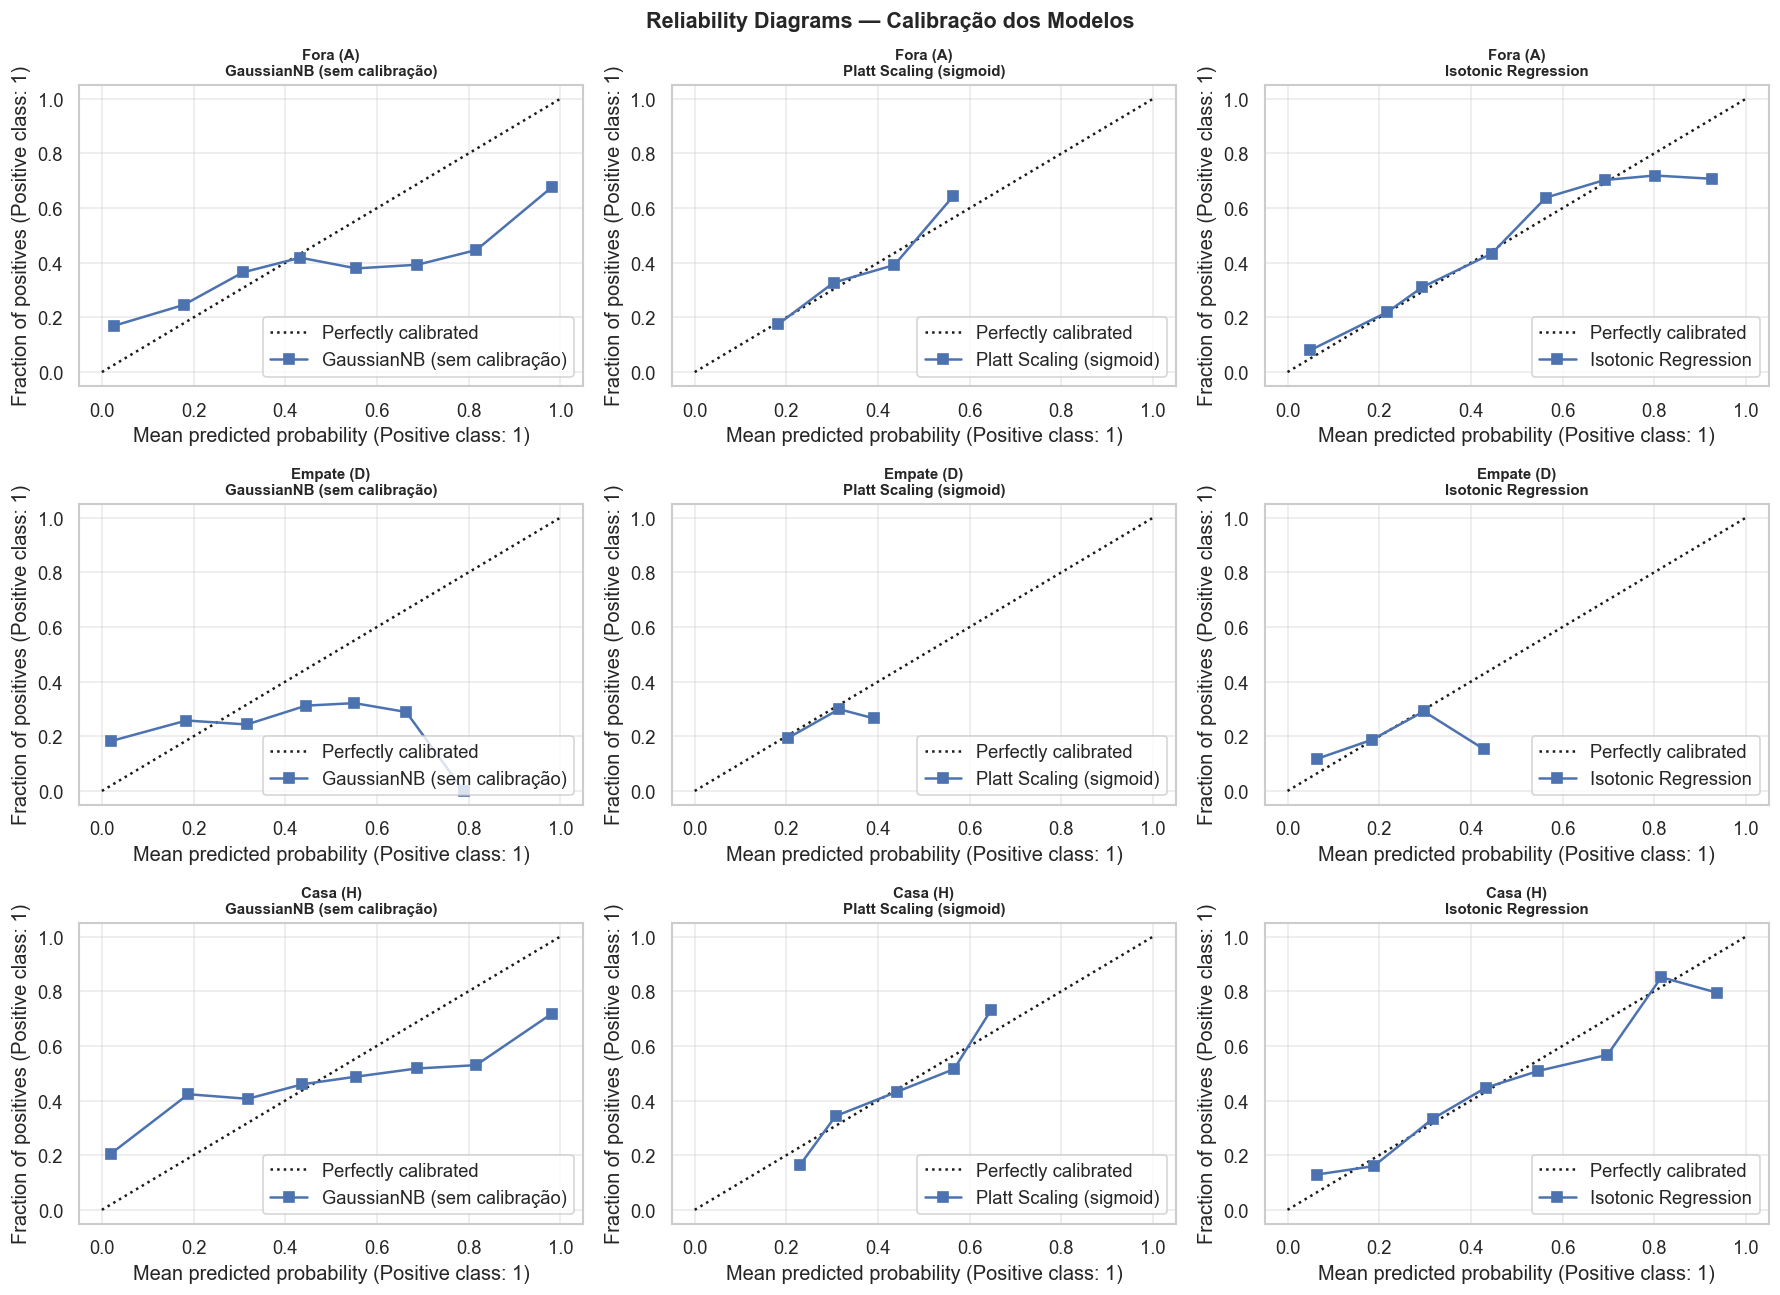

In [11]:
# Reliability Diagrams para cada classe
models_calib = [
    ('GaussianNB (sem calibração)', gnb_all, y_proba_gnb_all),
    ('Platt Scaling (sigmoid)', gnb_platt, y_proba_platt),
    ('Isotonic Regression', gnb_iso, y_proba_iso),
]

result_classes = gnb_all.classes_  # ['A', 'D', 'H']
class_labels = {'A': 'Fora (A)', 'D': 'Empate (D)', 'H': 'Casa (H)'}

fig, axes = plt.subplots(len(result_classes), len(models_calib),
                          figsize=(15, 11))

for col, (mname, model, y_proba) in enumerate(models_calib):
    for row, cls in enumerate(result_classes):
        ax = axes[row, col]
        cls_idx = list(result_classes).index(cls)
        y_bin = (y_test == cls).astype(int)
        prob_pos = y_proba[:, cls_idx]
        
        CalibrationDisplay.from_predictions(
            y_bin, prob_pos, n_bins=8, ax=ax,
            name=mname, color='#4C72B0'
        )
        ax.set_title(f'{class_labels[cls]}\n{mname}', fontsize=9, fontweight='bold')
        ax.grid(alpha=0.4)

plt.suptitle('Reliability Diagrams — Calibração dos Modelos', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p2_calibration_reliability.png', bbox_inches='tight')
plt.show()

In [12]:
# Métricas de calibração: Brier Score e Log Loss
print('=== Métricas de Calibração ===')
print(f'{"Modelo":<35} {"Brier Score":>12} {"Log Loss":>10} {"Accuracy":>10}')
print('-' * 70)

metric_models = [
    ('GNB (numérico)', gnb, y_proba_gnb, y_pred_gnb),
    ('CNB (categórico)', cnb, y_proba_cnb, y_pred_cnb),
    ('GNB (todas features)', gnb_all, y_proba_gnb_all, y_pred_gnb_all),
    ('GNB + Platt Scaling', gnb_platt, y_proba_platt, gnb_platt.predict(X_test_all)),
    ('GNB + Isotonic', gnb_iso, y_proba_iso, gnb_iso.predict(X_test_all)),
]

# Brier score multiclasse: média das brier scores por classe
def multiclass_brier(y_true, y_proba, classes):
    return np.mean([
        brier_score_loss((y_true == cls).astype(int), y_proba[:, i])
        for i, cls in enumerate(classes)
    ])

metrics_rows = []
for mname, model, y_proba, y_preds in metric_models:
    classes_m = model.classes_
    bs = multiclass_brier(y_test, y_proba, classes_m)
    ll = log_loss(y_test, y_proba, labels=classes_m)
    acc = accuracy_score(y_test, y_preds)
    metrics_rows.append({'Modelo': mname, 'Brier Score': bs, 'Log Loss': ll, 'Accuracy': acc})
    print(f'{mname:<35} {bs:>12.4f} {ll:>10.4f} {acc:>10.4f}')

metrics_df = pd.DataFrame(metrics_rows)

=== Métricas de Calibração ===
Modelo                               Brier Score   Log Loss   Accuracy
----------------------------------------------------------------------
GNB (numérico)                            0.2180     1.7289     0.5319
CNB (categórico)                          0.1963     1.0505     0.5679
GNB (todas features)                      0.2217     2.0142     0.5463
GNB + Platt Scaling                       0.1886     0.9577     0.5623
GNB + Isotonic                            0.1859     0.9539     0.5551


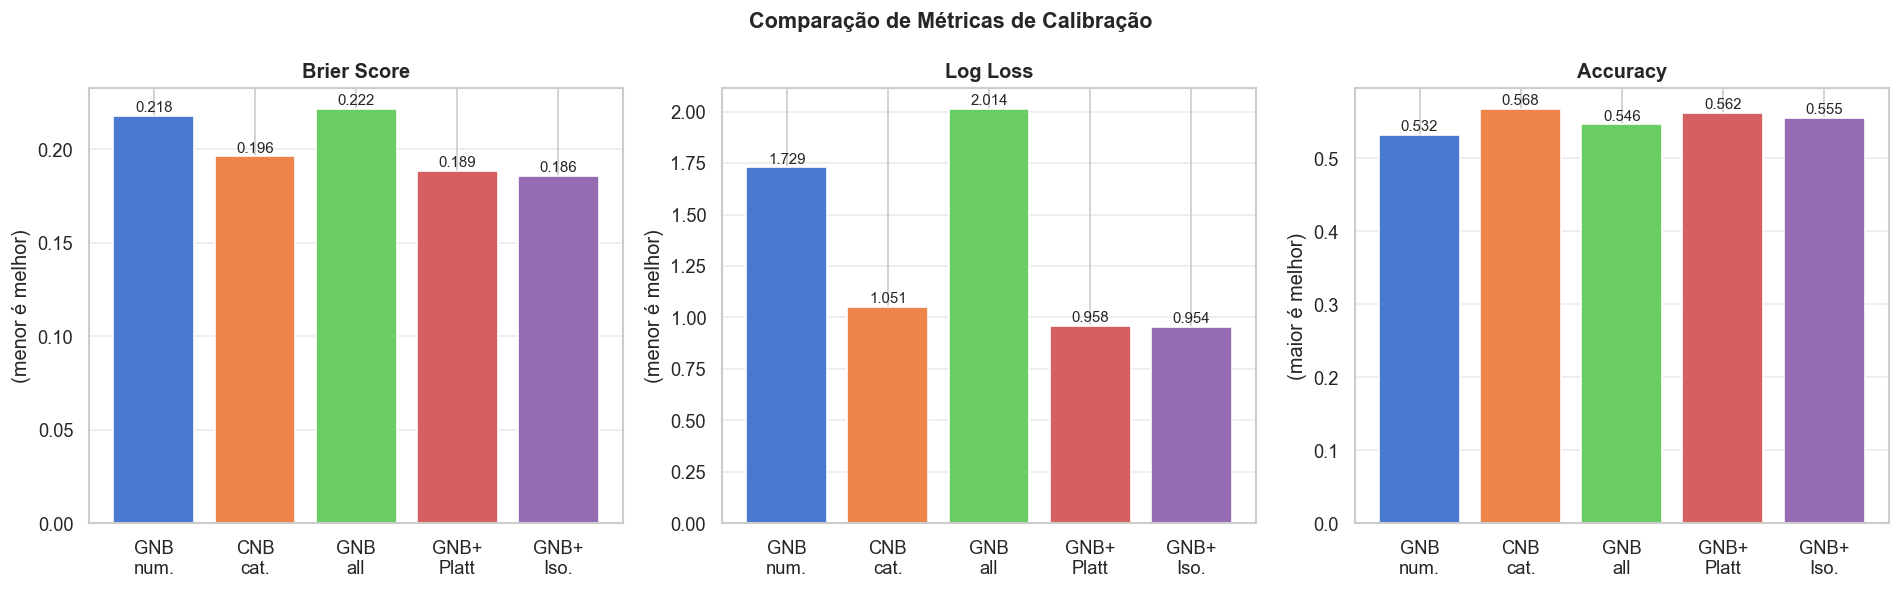

In [13]:
# Visualização das métricas de calibração
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors_bar = sns.color_palette('muted', len(metrics_df))
model_names_short = ['GNB\nnum.', 'CNB\ncat.', 'GNB\nall', 'GNB+\nPlatt', 'GNB+\nIso.']

for ax, metric in zip(axes, ['Brier Score', 'Log Loss', 'Accuracy']):
    bars = ax.bar(model_names_short, metrics_df[metric], color=colors_bar, edgecolor='white')
    for bar, val in zip(bars, metrics_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + metrics_df[metric].max() * 0.01,
                f'{val:.3f}', ha='center', fontsize=9)
    ax.set_title(metric, fontweight='bold')
    ax.grid(axis='y', alpha=0.4)
    if metric in ['Brier Score', 'Log Loss']:
        ax.set_ylabel('(menor é melhor)')
    else:
        ax.set_ylabel('(maior é melhor)')

plt.suptitle('Comparação de Métricas de Calibração', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p2_calibration_metrics.png', bbox_inches='tight')
plt.show()

## 5. Optimização Bayesiana de Hiperparâmetros

Utilizamos `BayesSearchCV` da biblioteca `scikit-optimize` para optimizar os hiperparâmetros do **GaussianNB** e da **Regressão Logística**, usando a log-loss como critério de optimização.

In [14]:
from skopt import BayesSearchCV
from skopt.space import Real, Categorical
from skopt.plots import plot_convergence
from sklearn.model_selection import TimeSeriesSplit

# Cross-validation temporal (não embaralhar dados de série temporal)
tscv = TimeSeriesSplit(n_splits=5)

# --- Optimização do GaussianNB (var_smoothing) ---
gnb_search_space = {
    'var_smoothing': Real(1e-11, 1e-1, prior='log-uniform')
}

gnb_bayes = BayesSearchCV(
    GaussianNB(),
    gnb_search_space,
    n_iter=30,
    scoring='neg_log_loss',
    cv=tscv,
    n_jobs=-1,
    random_state=42,
    verbose=0
)

gnb_bayes.fit(X_train_all, y_train)

print(f'GaussianNB — Melhor var_smoothing: {gnb_bayes.best_params_["var_smoothing"]:.2e}')
print(f'GaussianNB — Melhor Log Loss (CV): {-gnb_bayes.best_score_:.4f}')

GaussianNB — Melhor var_smoothing: 1.00e-01
GaussianNB — Melhor Log Loss (CV): 1.5711


In [15]:
# --- Optimização da Regressão Logística ---
lr_search_space = {
    'C': Real(1e-3, 10.0, prior='log-uniform'),
    'solver': Categorical(['lbfgs', 'saga']),
}

lr_bayes = BayesSearchCV(
    LogisticRegression(max_iter=1000, multi_class='multinomial'),
    lr_search_space,
    n_iter=30,
    scoring='neg_log_loss',
    cv=tscv,
    n_jobs=-1,
    random_state=42,
    verbose=0
)

lr_bayes.fit(X_train_all, y_train)

print(f'LogisticRegression — Melhores params: {lr_bayes.best_params_}')
print(f'LogisticRegression — Melhor Log Loss (CV): {-lr_bayes.best_score_:.4f}')

LogisticRegression — Melhores params: OrderedDict({'C': 0.00600156591950142, 'solver': 'lbfgs'})
LogisticRegression — Melhor Log Loss (CV): 0.9620


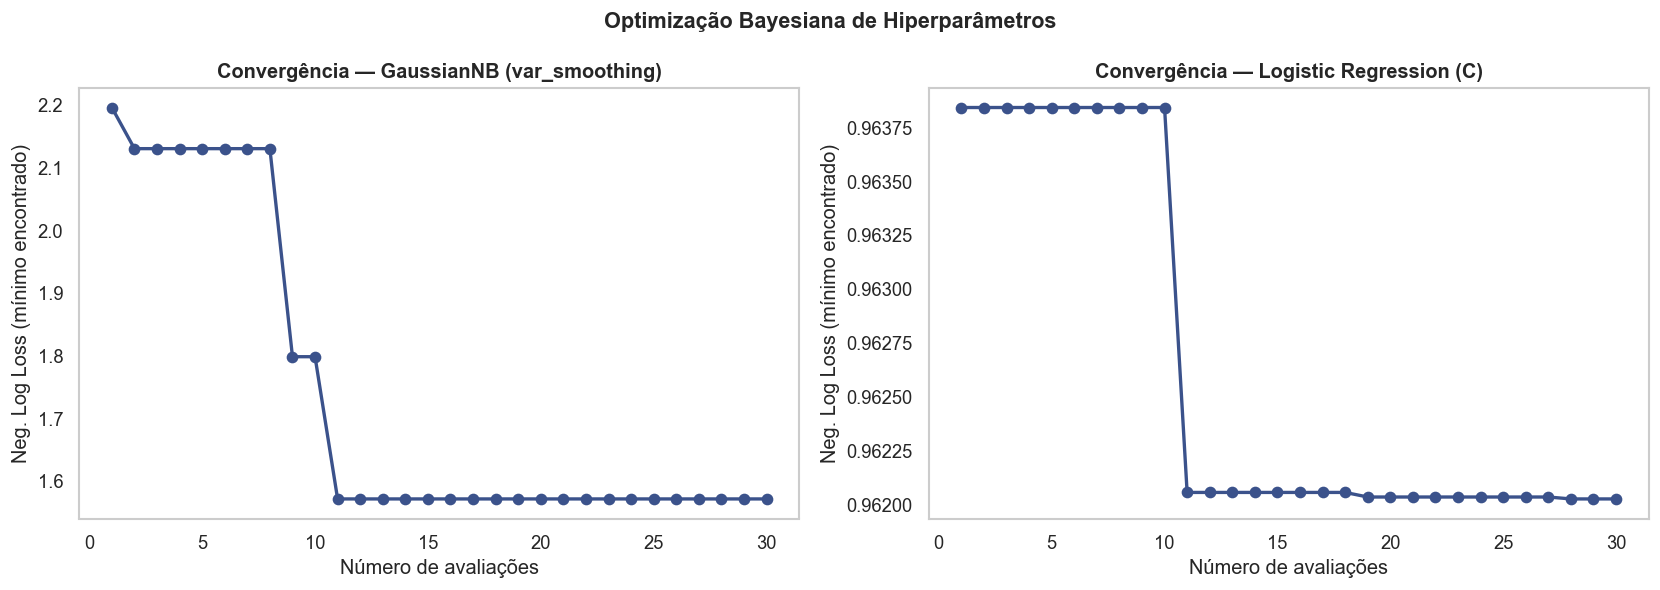

In [16]:
# Curvas de convergência da optimização Bayesiana
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_convergence(gnb_bayes.optimizer_results_[0], ax=axes[0])
axes[0].set_title('Convergência — GaussianNB (var_smoothing)', fontweight='bold')
axes[0].set_xlabel('Número de avaliações')
axes[0].set_ylabel('Neg. Log Loss (mínimo encontrado)')

plot_convergence(lr_bayes.optimizer_results_[0], ax=axes[1])
axes[1].set_title('Convergência — Logistic Regression (C)', fontweight='bold')
axes[1].set_xlabel('Número de avaliações')
axes[1].set_ylabel('Neg. Log Loss (mínimo encontrado)')

plt.suptitle('Optimização Bayesiana de Hiperparâmetros', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p2_bayesian_optimization.png', bbox_inches='tight')
plt.show()

In [17]:
# Avaliação dos modelos optimizados no conjunto de teste
best_gnb = gnb_bayes.best_estimator_
best_lr  = lr_bayes.best_estimator_

y_proba_best_gnb = best_gnb.predict_proba(X_test_all)
y_proba_best_lr  = best_lr.predict_proba(X_test_all)

print('=== Avaliação Final no Conjunto de Teste ===')
print(f'{"Modelo":<35} {"Brier Score":>12} {"Log Loss":>10} {"Accuracy":>10}')
print('-' * 70)

final_models = [
    ('GNB (baseline)', gnb_all, y_proba_gnb_all),
    ('GNB (optimizado)', best_gnb, y_proba_best_gnb),
    ('LR (optimizada)', best_lr, y_proba_best_lr),
    ('GNB + Platt (baseline calib)', gnb_platt, y_proba_platt),
]

final_metrics = []
for mname, model, y_proba in final_models:
    classes_m = model.classes_
    bs = multiclass_brier(y_test, y_proba, classes_m)
    ll = log_loss(y_test, y_proba, labels=classes_m)
    pred = model.predict(X_test_all)
    acc = accuracy_score(y_test, pred)
    final_metrics.append({'Modelo': mname, 'Brier Score': bs, 'Log Loss': ll, 'Accuracy': acc})
    print(f'{mname:<35} {bs:>12.4f} {ll:>10.4f} {acc:>10.4f}')

# Guardar melhor modelo e probabilidades para Parte 3
best_model_name = min(final_metrics, key=lambda x: x['Log Loss'])['Modelo']
print(f'\n→ Melhor modelo por Log Loss: {best_model_name}')

# Exportar probabilidades do melhor modelo para Parte 3
best_proba = y_proba_best_lr  # ajustar se necessário
best_classes = best_lr.classes_
np.save('best_model_proba_test.npy', best_proba)
np.save('best_model_classes.npy', best_classes)
print('Probabilidades guardadas em best_model_proba_test.npy')

=== Avaliação Final no Conjunto de Teste ===
Modelo                               Brier Score   Log Loss   Accuracy
----------------------------------------------------------------------
GNB (baseline)                            0.2217     2.0142     0.5463
GNB (optimizado)                          0.2103     1.5051     0.5431
LR (optimizada)                           0.1827     0.9315     0.5695
GNB + Platt (baseline calib)              0.1886     0.9577     0.5623

→ Melhor modelo por Log Loss: LR (optimizada)
Probabilidades guardadas em best_model_proba_test.npy
